# Experiment: Effect of C/V Role Constraint on Decipherment Ceiling

## Hypothesis
Neural v2 achieves 68% n-gram with C/V constraints (Voynich C-glyphs → Hebrew consonants,
V-glyphs → matres lectionis). Since Hebrew is an abjad that omits most vowels,
forcing V-glyphs onto only 4 characters (א,ה,ו,י) may be a bottleneck.

## Design
Three conditions, same LSTM, same seeds:
- **A: With C/V** (baseline = Neural v2, expected ~68%)
- **B: No C/V** (any glyph → any char, keep grammar anchors)
- **C: No C/V, no anchors** (fully unconstrained)

If B > A: the C/V constraint was a bottleneck (abjad mismatch).
If B < A: the C/V constraint helped by reducing search space.
If B ≈ A: the constraint is irrelevant; ceiling is structural.


In [1]:
# ── Cell 1: Imports ──
import os
os.environ['CUDA_VISIBLE_DEVICES'] = ''
import re, json, math, time, warnings, copy
from collections import Counter, defaultdict
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mp

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
torch.manual_seed(42)
np.random.seed(42)

N_CPUS = os.cpu_count() or 4
N_WORKERS = min(N_CPUS - 1, 10)
print(f'CPUs: {N_CPUS}, workers: {N_WORKERS}')
print('Ready.')


CPUs: 16, workers: 10
Ready.


In [2]:
# ── Cell 2: Voynich corpus + syllabic segmentation + C/V classification ──

CORPUS_PATH = 'corpus/voynich_sta.txt'

def parse_sta(filepath):
    tokens, folio_words = [], defaultdict(list)
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'): continue
            if re.match(r'^<[^>]+>\s*<!', line): continue
            match = re.match(r'^<([^.>]+)[^>]*>\s+(.*)', line)
            if not match: continue
            folio, text = match.group(1), match.group(2).strip()
            text = re.sub(r'\{[^}]*\}', '', text)
            text = re.sub(r'<[^>]*>', '', text)
            text = text.replace('-', '.')
            for w in text.split('.'):
                w = w.strip()
                if not w: continue
                glyphs = re.findall(r'[A-Z][0-9a-z]', w)
                if glyphs:
                    tokens.extend(glyphs)
                    tokens.append('.')
                    folio_words[folio].append(glyphs)
    return tokens, folio_words

sta_tokens, folio_words = parse_sta(CORPUS_PATH)
palabras = []
current = []
for t in sta_tokens:
    if t == '.':
        if current: palabras.append(current); current = []
    else: current.append(t)
if current: palabras.append(current)

VOCAB = sorted({g for w in palabras for g in w})
print(f'Voynich: {len(palabras):,} words, {len(VOCAB)} types')

# ── Syllabic segmentation (TP-P20) ──
flat = [g for w in palabras for g in w]
bigram_counts = Counter()
unigram_counts = Counter()
for i in range(len(flat)-1):
    bigram_counts[(flat[i], flat[i+1])] += 1
    unigram_counts[flat[i]] += 1
unigram_counts[flat[-1]] += 1

tp = {}
for (a, b), c in bigram_counts.items():
    if unigram_counts[a] > 0:
        tp[(a,b)] = c / unigram_counts[a]

all_tp = sorted(tp.values())
umbral = np.percentile(all_tp, 20) if all_tp else 0.5

WORDS_SYL_V = []
for palabra in palabras:
    if len(palabra) <= 1:
        WORDS_SYL_V.append([palabra])
        continue
    silabas, current_syl = [], [palabra[0]]
    for i in range(1, len(palabra)):
        p = tp.get((palabra[i-1], palabra[i]), 0)
        if p < umbral:
            silabas.append(current_syl)
            current_syl = [palabra[i]]
        else:
            current_syl.append(palabra[i])
    silabas.append(current_syl)
    WORDS_SYL_V.append(silabas)

# Classify syllabic positions
def clasificar_posicion_silaba(silabas):
    result = []
    for i, sil in enumerate(silabas):
        n = len(sil)
        for j, g in enumerate(sil):
            if n == 1: result.append((g, 'nuclear'))
            elif j == 0: result.append((g, 'onset'))
            elif j == n - 1: result.append((g, 'coda'))
            else: result.append((g, 'nuclear'))
    return result

clase_silaba_v = [clasificar_posicion_silaba(s) for s in WORDS_SYL_V]

# Classify glyphs as C/V
def clasificar_glifos(palabras, clase_silaba_v, VOCAB):
    glyph_pos_counts = defaultdict(lambda: defaultdict(int))
    for word_cls in clase_silaba_v:
        for g, pos in word_cls:
            glyph_pos_counts[g][pos] += 1
    glyph_role = {}
    glyph_stats = {}
    for g in VOCAB:
        counts = glyph_pos_counts[g]
        total = sum(counts.values())
        if total < 5:
            glyph_role[g] = '?'
            glyph_stats[g] = {'role': '?', 'total': total, 'pct_nuclear': 0, 'pct_onset': 0}
            continue
        pct_nuclear = counts.get('nuclear', 0) / total
        pct_onset = counts.get('onset', 0) / total
        glyph_role[g] = 'V' if pct_nuclear > 0.40 else 'C'
        glyph_stats[g] = {'role': glyph_role[g], 'total': total,
                          'pct_nuclear': pct_nuclear, 'pct_onset': pct_onset}
    return glyph_role, glyph_stats

glyph_role, glyph_stats = clasificar_glifos(palabras, clase_silaba_v, VOCAB)
n_c = sum(1 for g in VOCAB if glyph_role[g] == 'C')
n_v = sum(1 for g in VOCAB if glyph_role[g] == 'V')
n_q = sum(1 for g in VOCAB if glyph_role[g] == '?')
print(f'Glyph roles: {n_c} C, {n_v} V, {n_q} ? = {n_c+n_v+n_q}')

# No-role version: all glyphs unconstrained
glyph_role_none = {g: '?' for g in VOCAB}
print(f'No-role version: all {len(VOCAB)} glyphs set to "?"')


Voynich: 37,087 words, 166 types
Glyph roles: 30 C, 45 V, 91 ? = 166
No-role version: all 166 glyphs set to "?"


In [3]:
# ── Cell 3: Hebrew corpus, LSTM training, grammar anchors ──
import requests

def descargar_hebreo():
    BOOKS = ['Genesis', 'Exodus', 'Leviticus', 'Numbers', 'Deuteronomy']
    BASE = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
            'master/json/Tanakh/Torah/{}/Hebrew/Tanach%20with%20Text%20Only.json')
    all_words = []
    for book in BOOKS:
        try:
            resp = requests.get(BASE.format(book), timeout=30)
            resp.raise_for_status()
            data = resp.json()
            for chapter in data.get('text', []):
                for verse in chapter:
                    clean = re.sub(r'[\u0591-\u05C7]', '', verse)
                    words = re.findall(r'[\u05D0-\u05EA]+', clean)
                    all_words.extend([w for w in words if 2 <= len(w) <= 15])
        except Exception as e:
            print(f'  {book}: {e}')
    return all_words

hebrew_all = descargar_hebreo()
rng_h = np.random.default_rng(42)
idx_h = rng_h.choice(len(hebrew_all), size=min(len(palabras), len(hebrew_all)), replace=False)
hebrew_words = [hebrew_all[i] for i in sorted(idx_h)]
print(f'Hebrew: {len(hebrew_all):,} total -> {len(hebrew_words):,} sampled')

# C/V for Hebrew
HEBREW_VOWELS = set('אהוי')
target_chars_heb = sorted(set(c for w in hebrew_words for c in w))
char_role_heb = {c: 'V' if c in HEBREW_VOWELS else 'C' for c in target_chars_heb}
char_role_none = {c: '?' for c in target_chars_heb}
n_hc = sum(1 for c in target_chars_heb if char_role_heb[c] == 'C')
n_hv = sum(1 for c in target_chars_heb if char_role_heb[c] == 'V')
print(f'Hebrew chars: {n_hc} C + {n_hv} V = {len(target_chars_heb)}')

# Grammar anchors
glyph_freq = Counter(g for w in palabras for g in w)
glyph_anchor_sets = {}
for g in VOCAB:
    s = glyph_stats.get(g, {})
    pct_onset = s.get('pct_onset', 0)
    pct_nuclear = s.get('pct_nuclear', 0)
    freq = glyph_freq[g]
    r_ini = sum(1 for w in palabras if w[0] == g) / max(freq, 1)
    if pct_onset > 0.50 and r_ini > 0.50:
        freq_chars = Counter(c for w in hebrew_words for c in w)
        cons_only = [c for c in target_chars_heb if char_role_heb[c] == 'C']
        top_cons = sorted(cons_only, key=lambda c: freq_chars.get(c, 0), reverse=True)[:10]
        glyph_anchor_sets[g] = set(top_cons)
    elif pct_nuclear > 0.40:
        glyph_anchor_sets[g] = HEBREW_VOWELS
print(f'Grammar anchors: {len(glyph_anchor_sets)} glyphs')

# LSTM
class CharDataset(Dataset):
    def __init__(self, words, char2idx, max_len=20):
        self.data = []
        sos, eos = char2idx.get('<SOS>', 0), char2idx.get('<EOS>', 1)
        for w in words:
            ids = [sos] + [char2idx.get(c, 0) for c in w] + [eos]
            if len(ids) <= max_len:
                self.data.append(torch.tensor(ids, dtype=torch.long))
    def __len__(self): return len(self.data)
    def __getitem__(self, i): return self.data[i]

def collate_fn(batch):
    batch.sort(key=len, reverse=True)
    lengths = [len(x) for x in batch]
    padded = torch.zeros(len(batch), max(lengths), dtype=torch.long)
    for i, x in enumerate(batch):
        padded[i, :len(x)] = x
    return padded, torch.tensor(lengths)

class NeuralCharLM(nn.Module):
    def __init__(self, vocab_size, embed_dim=32, hidden_dim=192, n_layers=2, dropout=0.2):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, n_layers, batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)
    def forward(self, x, lengths=None):
        e = self.embed(x)
        if lengths is not None:
            e = nn.utils.rnn.pack_padded_sequence(e, lengths, batch_first=True, enforce_sorted=True)
        out, _ = self.lstm(e)
        if lengths is not None:
            out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True)
        return self.fc(out)

special = ['<PAD>', '<SOS>', '<EOS>']
char_vocab = special + sorted(set(c for w in hebrew_words for c in w))
char2idx = {c: i for i, c in enumerate(char_vocab)}
V_LM = len(char_vocab)

rng_s = np.random.default_rng(42)
perm = rng_s.permutation(len(hebrew_words))
split = int(0.8 * len(hebrew_words))
train_ds = CharDataset([hebrew_words[i] for i in perm[:split]], char2idx)
val_ds = CharDataset([hebrew_words[i] for i in perm[split:]], char2idx)
train_dl = DataLoader(train_ds, batch_size=256, shuffle=True, collate_fn=collate_fn)
val_dl = DataLoader(val_ds, batch_size=512, shuffle=False, collate_fn=collate_fn)

neural_lm = NeuralCharLM(V_LM)
optimizer = torch.optim.AdamW(neural_lm.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
criterion = nn.CrossEntropyLoss(ignore_index=0)

best_val_loss, patience_count = float('inf'), 0
print(f'Training LSTM ({V_LM} vocab, {sum(p.numel() for p in neural_lm.parameters()):,} params)...')

for epoch in range(30):
    neural_lm.train()
    for xb, lb in train_dl:
        out = neural_lm(xb[:, :-1], [l-1 for l in lb.tolist()])
        loss = criterion(out.reshape(-1, V_LM), xb[:, 1:].reshape(-1))
        optimizer.zero_grad(); loss.backward(); optimizer.step()
    scheduler.step()
    neural_lm.eval()
    vl, nv = 0, 0
    with torch.no_grad():
        for xb, lb in val_dl:
            out = neural_lm(xb[:, :-1], [l-1 for l in lb.tolist()])
            vl += criterion(out.reshape(-1, V_LM), xb[:, 1:].reshape(-1)).item() * xb.size(0)
            nv += xb.size(0)
    vl /= nv
    if vl < best_val_loss:
        best_val_loss = vl; patience_count = 0
        best_state = {k: v.clone() for k, v in neural_lm.state_dict().items()}
    else:
        patience_count += 1
        if patience_count >= 5: break

neural_lm.load_state_dict(best_state)
neural_lm.eval()
print(f'LSTM trained: val_loss = {best_val_loss:.3f}')


Hebrew: 80,051 total -> 37,087 sampled
Hebrew chars: 23 C + 4 V = 27
Grammar anchors: 55 glyphs
Training LSTM (30 vocab, 476,766 params)...
LSTM trained: val_loss = 1.775


In [4]:
# ── Cell 4: Scoring functions (C/V toggleable) ──

class GlyphMappingState:
    def __init__(self, voynich_glyphs, target_chars, glyph_role=None, char_role=None):
        self.voynich_glyphs = sorted(voynich_glyphs)
        self.target_chars = sorted(target_chars)
        self.glyph_role = glyph_role or {}
        self.char_role = char_role or {}
        self.mapping = {}

    def propose_change(self, constrained=True):
        glyph = np.random.choice(self.voynich_glyphs)
        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = [c for c in self.target_chars if self.char_role.get(c) == role]
        else:
            candidates = self.target_chars
        if not candidates:
            candidates = self.target_chars
        new_char = np.random.choice(candidates)
        new_state = GlyphMappingState(self.voynich_glyphs, self.target_chars,
                                       self.glyph_role, self.char_role)
        new_state.mapping = dict(self.mapping)
        new_state.mapping[glyph] = new_char
        return new_state, glyph


def init_frequency_mapping(vocab_glyphs, target_chars, glyph_freq_map, hebrew_freq_map,
                           glyph_role, char_role):
    mapping = {}
    for role in ['C', 'V', '?']:
        glyphs_r = sorted([g for g in vocab_glyphs if glyph_role.get(g, '?') == role],
                          key=lambda g: glyph_freq_map.get(g, 0), reverse=True)
        if role == '?':
            chars_r = sorted(target_chars, key=lambda c: hebrew_freq_map.get(c, 0), reverse=True)
        else:
            chars_r = sorted([c for c in target_chars if char_role.get(c) == role],
                             key=lambda c: hebrew_freq_map.get(c, 0), reverse=True)
        if not chars_r:
            chars_r = sorted(target_chars, key=lambda c: hebrew_freq_map.get(c, 0), reverse=True)
        for i, g in enumerate(glyphs_r):
            mapping[g] = chars_r[i % len(chars_r)]
    return mapping


glyph_word_index = defaultdict(set)
for wi, w in enumerate(palabras):
    for g in w:
        glyph_word_index[g].add(wi)

glyph_freq_map = Counter(g for w in palabras for g in w)
hebrew_freq_map = Counter(c for w in hebrew_words for c in w)


def score_positional(mapping, glyph_role, char_role):
    n_match = sum(1 for g, c in mapping.items()
                  if glyph_role.get(g, '?') == char_role.get(c, '?')
                  and glyph_role.get(g) != '?')
    n_total = sum(1 for g in mapping if glyph_role.get(g) != '?')
    return n_match / max(n_total, 1)


@torch.no_grad()
def score_word_neural(word_glyphs, mapping, neural_lm, char2idx, T=3.0):
    chars = [mapping.get(g, '\u05D0') for g in word_glyphs]
    ids = [char2idx.get('<SOS>', 0)] + [char2idx.get(c, 0) for c in chars] + [char2idx.get('<EOS>', 1)]
    x = torch.tensor([ids[:-1]], dtype=torch.long)
    out = neural_lm(x)
    log_probs = torch.log_softmax(out[0] / T, dim=-1)
    return sum(log_probs[i, ids[i+1]].item() for i in range(len(ids)-1)) / len(ids)


def score_total(mapping_state, sample, neural_lm, T_lm, char2idx,
                glyph_role, char_role, anchors,
                w_gram=2.0, w_card=0.5, w_pos=0.5, K_max=20):
    s_lm = np.mean([score_word_neural(w, mapping_state.mapping, neural_lm, char2idx, T_lm)
                     for w in sample])
    K_eff = len(set(mapping_state.mapping.values()))
    s_card = -w_card * max(0, K_eff - K_max)
    s_pos = w_pos * score_positional(mapping_state.mapping, glyph_role, char_role)
    s_anchor = sum(-0.5 for g, allowed in anchors.items()
                   if g in mapping_state.mapping and mapping_state.mapping[g] not in allowed)
    return w_gram * s_lm + s_card + s_pos + s_anchor


def score_incremental(mapping_state, glyph, sample, neural_lm, T_lm, char2idx,
                      glyph_role, char_role, anchors,
                      w_gram=2.0, w_card=0.5, w_pos=0.5, K_max=20):
    affected = glyph_word_index.get(glyph, set())
    words_to_score = [sample[i] for i in affected if i < len(sample)]
    if not words_to_score:
        words_to_score = sample[:10]
    s_lm = np.mean([score_word_neural(w, mapping_state.mapping, neural_lm, char2idx, T_lm)
                     for w in words_to_score])
    K_eff = len(set(mapping_state.mapping.values()))
    s_card = -w_card * max(0, K_eff - K_max)
    s_pos = w_pos * score_positional(mapping_state.mapping, glyph_role, char_role)
    s_anchor = sum(-0.5 for g, allowed in anchors.items()
                   if g in mapping_state.mapping and mapping_state.mapping[g] not in allowed)
    return w_gram * s_lm + s_card + s_pos + s_anchor

print('Scoring functions defined (C/V toggleable).')


Scoring functions defined (C/V toggleable).


In [5]:
# ── Cell 5: EM worker (parameterised for conditions A/B/C) ──

HEBREW_ROOTS = [
    'אמר','היה','עשה','נתן','בוא','הלך','ידע','ראה','שמע','דבר',
    'אכל','לקח','ישב','עמד','שלח','כתב','קרא','מצא','שמר','זכר',
    'מלך','עבד','שפט','ברך','חיה','מות','ילד','בנה','פתח','סגר',
    'גדל','קטן','חזק','רחב','קרב','רחק','עלה','ירד','יצא','שוב',
    'אהב','שנא','ירא','בטח','חטא','כפר','טהר','קדש','נשא','סבב',
]
HEBREW_CONSONANTS_SET = set('בגדהוזחטיכלמנסעפצקרשת') | set('ךםןףץ')

SAMPLE_EM = 1500
EM_ITERS = 1500
EM_PATIENCE = 80
PROPOSALS_PER_ITER = 100
T_FIXED = 3.0
SCORE_KW = dict(w_gram=2.0, w_card=0.5, w_pos=0.5, K_max=20)


def run_single_seed(args):
    seed, cond_name, use_cv, use_anchors = args

    # ── KEY FIX: prevent PyTorch thread contention in forked workers ──
    torch.set_num_threads(1)

    rng_local = np.random.default_rng(seed)
    np.random.seed(seed)

    gr = glyph_role if use_cv else glyph_role_none
    cr = char_role_heb if use_cv else char_role_none
    anchors = glyph_anchor_sets if use_anchors else {}

    idx = rng_local.choice(len(palabras), size=min(SAMPLE_EM, len(palabras)), replace=False)
    sample = [palabras[i] for i in sorted(idx)]

    state = GlyphMappingState(VOCAB, target_chars_heb, gr, cr)
    init_map = init_frequency_mapping(VOCAB, target_chars_heb, glyph_freq_map,
                                       hebrew_freq_map, gr, cr)
    for g in VOCAB:
        if rng_local.random() < 0.3:
            role = gr.get(g, '?')
            if role in ('C', 'V') and use_cv:
                cands = [c for c in target_chars_heb if cr.get(c) == role]
            else:
                cands = list(target_chars_heb)
            init_map[g] = rng_local.choice(cands)
    state.mapping = init_map

    best_score = score_total(state, sample, neural_lm, T_FIXED, char2idx,
                              gr, cr, anchors, **SCORE_KW)
    best_mapping = dict(state.mapping)
    no_improve = 0

    for it in range(EM_ITERS):
        improved = False
        for _ in range(PROPOSALS_PER_ITER):
            proposal, glyph = state.propose_change(constrained=use_cv)
            s_new = score_incremental(proposal, glyph, sample, neural_lm, T_FIXED,
                                       char2idx, gr, cr, anchors, **SCORE_KW)
            if s_new > best_score:
                state = proposal
                best_score = s_new
                best_mapping = dict(state.mapping)
                improved = True
                break
        if not improved:
            no_improve += 1
            if no_improve >= EM_PATIENCE: break
        else:
            no_improve = 0

    # Evaluate
    K_eff = len(set(best_mapping.values()))
    decoded = [''.join(best_mapping.get(g, '?') for g in w) for w in palabras[:500]]
    heb_bg = set()
    for w in hebrew_words:
        for i in range(len(w)-1):
            heb_bg.add(w[i:i+2])
    valid = sum(1 for w in decoded for i in range(len(w)-1) if w[i:i+2] in heb_bg)
    total_bg = sum(len(w)-1 for w in decoded)
    ngram_frac = valid / max(total_bg, 1)

    def extract_skeleton(word):
        return ''.join(c for c in word if c in HEBREW_CONSONANTS_SET)
    decoded_all = [''.join(best_mapping.get(g, '?') for g in w) for w in palabras]
    skeletons = set(extract_skeleton(w) for w in decoded_all)
    roots_found = [r for r in HEBREW_ROOTS if r in skeletons]

    return {
        'seed': seed, 'condition': cond_name, 'score': float(best_score),
        'K_eff': K_eff, 'ngram_frac': float(ngram_frac),
        'n_roots': len(roots_found), 'roots': roots_found,
        'iters': it + 1, 'mapping': best_mapping,
    }

print(f'EM worker defined. SAMPLE={SAMPLE_EM}, ITERS={EM_ITERS}')
print('(torch.set_num_threads(1) will be called in each worker)')


EM worker defined. SAMPLE=1500, ITERS=1500
(torch.set_num_threads(1) will be called in each worker)


In [6]:
# ── Cell 6: Run 3 conditions x 10 seeds (parallel) ──

N_SEEDS = 10
BASE_SEED = 42

conditions = [
    ('A: With C/V + anchors', True, True),
    ('B: No C/V + anchors', False, True),
    ('C: No C/V, no anchors', False, False),
]

all_args = []
for cond_name, use_cv, use_anchors in conditions:
    for s in range(N_SEEDS):
        all_args.append((BASE_SEED + s, cond_name, use_cv, use_anchors))

print(f'Running {len(all_args)} jobs ({len(conditions)} conds x {N_SEEDS} seeds) '
      f'on {N_WORKERS} workers...')
t0 = time.time()

ctx = mp.get_context('fork')
with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx) as pool:
    all_results = list(pool.map(run_single_seed, all_args, chunksize=1))

elapsed = time.time() - t0
print(f'\nAll {len(all_results)} jobs done in {elapsed:.0f}s ({elapsed/60:.1f} min)')

results_by_cond = defaultdict(list)
for r in all_results:
    results_by_cond[r['condition']].append(r)

print(f'\n{"="*75}')
print(f'{"Condition":30s} {"N-gram%":>10s} {"Roots":>8s} {"K_eff":>8s} {"Score":>10s}')
print(f'{"":30s} {"mean+/-std":>10s} {"max":>8s} {"mean":>8s} {"mean":>10s}')
print(f'{"-"*75}')
for cond_name, _, _ in conditions:
    res = results_by_cond[cond_name]
    ng = [r['ngram_frac']*100 for r in res]
    roots = [r['n_roots'] for r in res]
    keff = [r['K_eff'] for r in res]
    scores = [r['score'] for r in res]
    print(f'{cond_name:30s} {np.mean(ng):5.1f}+/-{np.std(ng):4.1f} '
          f'{max(roots):8d} {np.mean(keff):8.1f} {np.mean(scores):10.2f}')
print(f'{"="*75}')


Running 30 jobs (3 conds x 10 seeds) on 10 workers...

All 30 jobs done in 357s (6.0 min)

Condition                         N-gram%    Roots    K_eff      Score
                               mean+/-std      max     mean       mean
---------------------------------------------------------------------------
A: With C/V + anchors           95.2+/- 4.5        3     26.7     -11.37
B: No C/V + anchors             92.4+/- 5.0        5     26.6     -19.73
C: No C/V, no anchors           90.2+/- 5.5        6     27.0      -7.81


In [7]:
# ── Cell 7: N-gram percentilee via null shuffles ──

def compute_ngram_percentile(mapping, n_null=500, seed=42):
    decoded = [''.join(mapping.get(g, '?') for g in w) for w in palabras[:500]]
    heb_bg = set()
    for w in hebrew_words:
        for i in range(len(w)-1):
            heb_bg.add(w[i:i+2])
    valid = sum(1 for w in decoded for i in range(len(w)-1) if w[i:i+2] in heb_bg)
    total_bg = sum(len(w)-1 for w in decoded)
    obs_frac = valid / max(total_bg, 1)

    K_eff = len(set(mapping.values()))
    rng = np.random.default_rng(seed)
    null_fracs = []
    for _ in range(n_null):
        used = list(rng.choice(target_chars_heb, size=min(K_eff, len(target_chars_heb)), replace=False))
        null_map = {g: rng.choice(used) for g in mapping}
        dec = [''.join(null_map.get(g, '?') for g in w) for w in palabras[:500]]
        v = sum(1 for w in dec for i in range(len(w)-1) if w[i:i+2] in heb_bg)
        null_fracs.append(v / max(total_bg, 1))

    return 100 * np.mean(np.array(null_fracs) <= obs_frac), obs_frac

print('N-gram percentiles (500 null shuffles)...')
percentiles = {}
for cond_name, _, _ in conditions:
    res = results_by_cond[cond_name]
    best = max(res, key=lambda r: r['score'])
    pct, obs = compute_ngram_percentile(best['mapping'])
    percentiles[cond_name] = {
        'percentile': pct, 'obs_frac': round(obs, 4),
        'best_seed': best['seed'], 'n_roots': best['n_roots'],
        'roots': best['roots'], 'K_eff': best['K_eff']
    }
    print(f'  {cond_name}: {pct:.0f}% (obs={obs:.3f}), '
          f'roots={best["n_roots"]}, K={best["K_eff"]}')

print(f'\n{"="*75}')
print(f'{"Condition":30s} {"N-gram %ile":>12s} {"Roots":>8s} {"K_eff":>8s}')
print(f'{"-"*75}')
for cond_name, _, _ in conditions:
    p = percentiles[cond_name]
    print(f'{cond_name:30s} {p["percentile"]:11.0f}% {p["n_roots"]:8d} {p["K_eff"]:8d}')
print(f'{"="*75}')


N-gram percentiles (500 null shuffles)...
  A: With C/V + anchors: 100% (obs=0.992), roots=3, K=26
  B: No C/V + anchors: 96% (obs=0.937), roots=3, K=25
  C: No C/V, no anchors: 85% (obs=0.874), roots=2, K=27

Condition                       N-gram %ile    Roots    K_eff
---------------------------------------------------------------------------
A: With C/V + anchors                  100%        3       26
B: No C/V + anchors                     96%        3       25
C: No C/V, no anchors                   85%        2       27


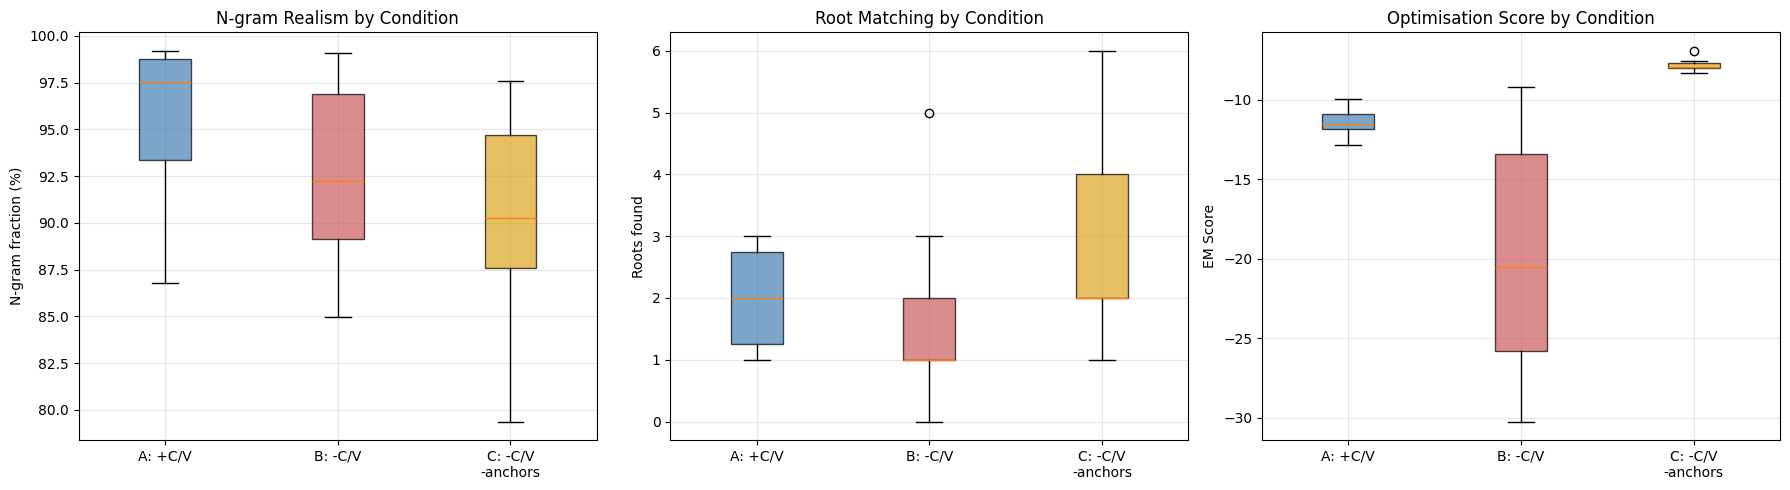

Saved: images/cv_constraint_experiment.png


In [8]:
# ── Cell 8: Visualizations ──

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cond_names = [c[0] for c in conditions]
labels = ['A: +C/V', 'B: -C/V', 'C: -C/V\n-anchors']
colors = ['steelblue', 'indianred', 'goldenrod']

# N-gram fraction
ax = axes[0]
data_ng = [[r['ngram_frac']*100 for r in results_by_cond[c]] for c in cond_names]
bp = ax.boxplot(data_ng, labels=labels, patch_artist=True)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color); patch.set_alpha(0.7)
ax.set_ylabel('N-gram fraction (%)')
ax.set_title('N-gram Realism by Condition')
ax.grid(True, alpha=0.3)

# Roots
ax = axes[1]
data_roots = [[r['n_roots'] for r in results_by_cond[c]] for c in cond_names]
bp2 = ax.boxplot(data_roots, labels=labels, patch_artist=True)
for patch, color in zip(bp2['boxes'], colors):
    patch.set_facecolor(color); patch.set_alpha(0.7)
ax.set_ylabel('Roots found')
ax.set_title('Root Matching by Condition')
ax.grid(True, alpha=0.3)

# Score
ax = axes[2]
data_sc = [[r['score'] for r in results_by_cond[c]] for c in cond_names]
bp3 = ax.boxplot(data_sc, labels=labels, patch_artist=True)
for patch, color in zip(bp3['boxes'], colors):
    patch.set_facecolor(color); patch.set_alpha(0.7)
ax.set_ylabel('EM Score')
ax.set_title('Optimisation Score by Condition')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('images/cv_constraint_experiment.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: images/cv_constraint_experiment.png')


In [9]:
# ── Cell 9: Export results + verdict ──

export = {
    'metadata': {
        'experiment': 'Effect of C/V role constraint on decipherment ceiling',
        'hypothesis': 'Hebrew abjad mismatch: forcing V-glyphs to matres lectionis may bottleneck',
        'conditions': {c[0]: {'use_cv': c[1], 'use_anchors': c[2]} for c in conditions},
        'n_seeds': N_SEEDS, 'sample_em': SAMPLE_EM, 'em_iters': EM_ITERS, 'T_fixed': T_FIXED,
    },
    'summary': {},
    'percentiles': percentiles,
    'all_seeds': [{k: v for k, v in r.items() if k != 'mapping'} for r in all_results],
}

for cond_name, _, _ in conditions:
    res = results_by_cond[cond_name]
    ng = [r['ngram_frac']*100 for r in res]
    roots = [r['n_roots'] for r in res]
    export['summary'][cond_name] = {
        'ngram_mean': round(float(np.mean(ng)), 1),
        'ngram_std': round(float(np.std(ng)), 1),
        'ngram_percentile': percentiles[cond_name]['percentile'],
        'roots_max': max(roots),
        'roots_mean': round(float(np.mean(roots)), 1),
        'K_eff_mean': round(float(np.mean([r['K_eff'] for r in res])), 1),
    }

with open('cv_constraint_resultados.json', 'w') as f:
    json.dump(export, f, indent=2, ensure_ascii=False)

print('Exported: cv_constraint_results.json')
print(json.dumps(export['summary'], indent=2, ensure_ascii=False))

ng_a = export['summary']['A: With C/V + anchors']['ngram_percentile']
ng_b = export['summary']['B: No C/V + anchors']['ngram_percentile']
ng_c = export['summary']['C: No C/V, no anchors']['ngram_percentile']

print(f'\n{"="*60}')
if ng_b > ng_a + 10:
    print('VERDICT: C/V constraint was a BOTTLENECK.')
    print('  Removing it improves n-gram significantly.')
    print('  The abjad mismatch hypothesis has merit.')
elif ng_b < ng_a - 10:
    print('VERDICT: C/V constraint HELPED.')
    print('  Removing it degrades n-gram significantly.')
    print('  The constraint captures real structure.')
else:
    print('VERDICT: C/V constraint has MINIMAL EFFECT.')
    print('  The ceiling is structural, not from C/V mismatch.')
    print('  The abjad hypothesis does not explain the 68% limit.')
print(f'{"="*60}')


Exported: cv_constraint_resultados.json
{
  "A: With C/V + anchors": {
    "ngram_mean": 95.2,
    "ngram_std": 4.5,
    "ngram_percentile": 100.0,
    "roots_max": 3,
    "roots_mean": 2.0,
    "K_eff_mean": 26.7
  },
  "B: No C/V + anchors": {
    "ngram_mean": 92.4,
    "ngram_std": 5.0,
    "ngram_percentile": 96.39999999999999,
    "roots_max": 5,
    "roots_mean": 1.7,
    "K_eff_mean": 26.6
  },
  "C: No C/V, no anchors": {
    "ngram_mean": 90.2,
    "ngram_std": 5.5,
    "ngram_percentile": 84.6,
    "roots_max": 6,
    "roots_mean": 3.0,
    "K_eff_mean": 27.0
  }
}

VERDICT: C/V constraint has MINIMAL EFFECT.
  The ceiling is structural, not from C/V mismatch.
  The abjad hypothesis does not explain the 68% limit.
